# Tugas Praktikum 4: Association Rule Mining dengan Apriori
**Nama:** Rafa Rizki Aira Swala  
**NRP:** 50425017  
**Dataset:** Online Retail

## 1. Import Library

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 60)
sns.set_style('whitegrid')
%matplotlib inline

## 2. Load Dataset

Dataset berisi transaksi ritel online toko di Inggris periode Desember 2010 – Desember 2011.

**Atribut:** `InvoiceNo`, `StockCode`, `Description`, `Quantity`, `InvoiceDate`, `UnitPrice`, `CustomerID`, `Country`.

In [4]:
df = pd.read_excel('Online Retail.xlsx')

print("Shape dataset:", df.shape)
print("\n5 Baris Pertama:")
df.head()

print("Info Dataset")
df.info()

Shape dataset: (541909, 8)

5 Baris Pertama:
Info Dataset
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


## 3. Eksplorasi Data (EDA)

### 3.1 Statistik Awal Sebelum Cleaning

In [5]:
n_rows_awal = len(df)
n_invoice_awal = df['InvoiceNo'].nunique()

print(f"Jumlah baris awal    : {n_rows_awal:,}")
print(f"Jumlah invoice awal  : {n_invoice_awal:,}")

Jumlah baris awal    : 541,909
Jumlah invoice awal  : 25,900


In [6]:
print("Missing value per kolom:")
print(df[['InvoiceNo', 'Description', 'Quantity']].isnull().sum())

# Transaksi yang dibatalkan (InvoiceNo diawali 'C')
n_cancel = df['InvoiceNo'].astype(str).str.startswith('C').sum()
print(f"\nTransaksi dibatalkan (diawali 'C'): {n_cancel:,}")

# Quantity negatif atau nol
n_qty_invalid = (df['Quantity'] <= 0).sum()
print(f"Baris dengan Quantity <= 0      : {n_qty_invalid:,}")

Missing value per kolom:
InvoiceNo         0
Description    1454
Quantity          0
dtype: int64

Transaksi dibatalkan (diawali 'C'): 9,288
Baris dengan Quantity <= 0      : 10,624


### 3.2 Statistik per Negara dan Top Produk

In [7]:
print("Top 5 Negara berdasarkan jumlah transaksi:")
print(df['Country'].value_counts().head())

print("\nTop 10 Produk paling sering dibeli:")
df_positive = df[df['Quantity'] > 0]
top_products = df_positive.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)
top_products

Top 5 Negara berdasarkan jumlah transaksi:
Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Name: count, dtype: int64

Top 10 Produk paling sering dibeli:


Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     55047
JUMBO BAG RED RETROSPOT               48478
WHITE HANGING HEART T-LIGHT HOLDER    37895
POPCORN HOLDER                        36761
ASSORTED COLOUR BIRD ORNAMENT         36461
PACK OF 72 RETROSPOT CAKE CASES       36419
RABBIT NIGHT LIGHT                    30788
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

### 3.3 Distribusi Jumlah Item per Transaksi

C:\Users\airal\AppData\Local\Temp\ipykernel_17584\1633140325.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(items_per_invoice.dropna(), vert=False)


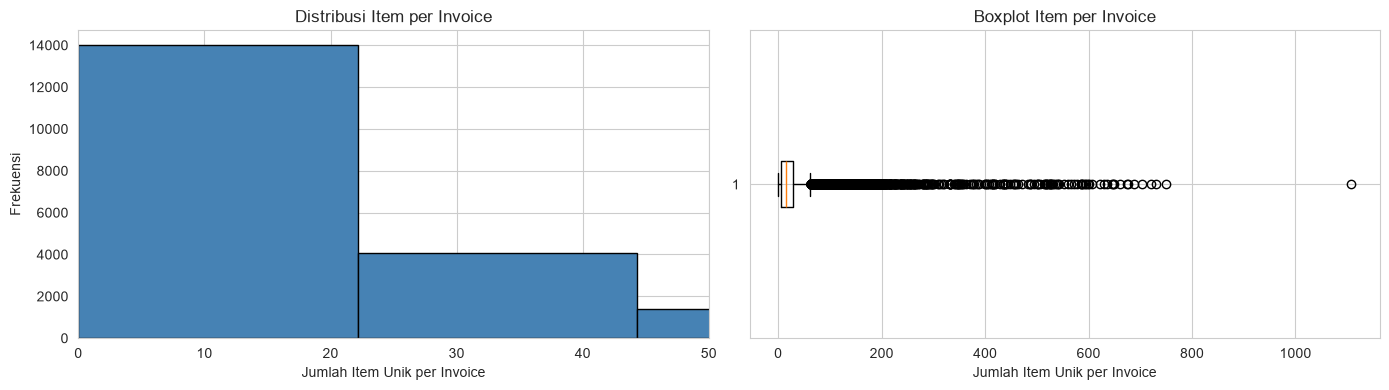

Rata-rata item per invoice : 25.09
Median item per invoice    : 15
Max item per invoice       : 1108


In [8]:
items_per_invoice = df_positive.groupby('InvoiceNo')['Description'].nunique()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Histogram item per invoice
axes[0].hist(items_per_invoice, bins=50, color='steelblue', edgecolor='k')
axes[0].set_xlabel('Jumlah Item Unik per Invoice')
axes[0].set_ylabel('Frekuensi')
axes[0].set_title('Distribusi Item per Invoice')
axes[0].set_xlim(0, 50)

# Boxplot
axes[1].boxplot(items_per_invoice.dropna(), vert=False)
axes[1].set_xlabel('Jumlah Item Unik per Invoice')
axes[1].set_title('Boxplot Item per Invoice')

plt.tight_layout()
plt.show()

print(f"Rata-rata item per invoice : {items_per_invoice.mean():.2f}")
print(f"Median item per invoice    : {items_per_invoice.median():.0f}")
print(f"Max item per invoice       : {items_per_invoice.max()}")

## 4. Pembersihan Data

Langkah cleaning:
1. Hapus baris dengan `Description` kosong
2. Hapus transaksi dibatalkan (`InvoiceNo` diawali 'C')
3. Hapus baris dengan `Quantity <= 0`
4. Normalisasi `Description` (strip spasi)

In [9]:
df_clean = df.copy()

# 1. Hapus Description kosong
df_clean = df_clean.dropna(subset=['Description'])

# 2. Hapus transaksi dibatalkan (InvoiceNo diawali 'C')
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]

# 3. Hapus Quantity negatif atau nol
df_clean = df_clean[df_clean['Quantity'] > 0]

# 4. Normalisasi Description
df_clean['Description'] = df_clean['Description'].str.strip()

df_clean = df_clean.reset_index(drop=True)

n_rows_akhir = len(df_clean)
n_invoice_akhir = df_clean['InvoiceNo'].nunique()

summary_clean = pd.DataFrame({
    'Sebelum': [n_rows_awal, n_invoice_awal],
    'Sesudah': [n_rows_akhir, n_invoice_akhir],
    'Dihapus': [n_rows_awal - n_rows_akhir, n_invoice_awal - n_invoice_akhir]
}, index=['Jumlah Baris', 'Jumlah Invoice'])

print(f"Shape setelah cleaning: {df_clean.shape}")
summary_clean

Shape setelah cleaning: (530693, 8)


,Sebelum,Sesudah,Dihapus
Jumlah Baris,541909,530693,11216
Jumlah Invoice,25900,20136,5764


**Insight:**

Pembersihan data penting sebelum Association Rule Mining karena:

1. **Description kosong** tidak bisa jadi item dalam itemset
2. **Transaksi dibatalkan** (`C...`) adalah retur, bukan pembelian
3. **Quantity negatif/0** mengindikasikan retur atau error input

Setelah cleaning, dataset merepresentasikan **transaksi pembelian yang valid** dan siap dianalisis.

## 5. Persiapan Data untuk Association Rule

Data diubah menjadi format transaksi berbasis invoice, lalu di-one-hot encode agar bisa diproses `mlxtend`.

### 5.1 Grouping Transaksi per Invoice

In [10]:
transactions = df_clean.groupby('InvoiceNo')['Description'].apply(
    lambda x: list(x.unique())
)

print(f"Jumlah transaksi (invoice) unik : {len(transactions):,}")
print(f"Rata-rata item per transaksi    : {transactions.apply(len).mean():.2f}")
print(f"Maksimum item per transaksi     : {transactions.apply(len).max()}")
print("\nContoh 3 transaksi pertama:")
for inv, items in transactions.head(3).items():
    print(f"  {inv}: {items[:5]}{'...' if len(items) > 5 else ''}")

Jumlah transaksi (invoice) unik : 20,136
Rata-rata item per transaksi    : 25.82
Maksimum item per transaksi     : 1108

Contoh 3 transaksi pertama:
  536365: ['WHITE HANGING HEART T-LIGHT HOLDER', 'WHITE METAL LANTERN', 'CREAM CUPID HEARTS COAT HANGER', 'KNITTED UNION FLAG HOT WATER BOTTLE', 'RED WOOLLY HOTTIE WHITE HEART.']...
  536366: ['HAND WARMER UNION JACK', 'HAND WARMER RED POLKA DOT']
  536367: ['ASSORTED COLOUR BIRD ORNAMENT', "POPPY'S PLAYHOUSE BEDROOM", "POPPY'S PLAYHOUSE KITCHEN", 'FELTCRAFT PRINCESS CHARLOTTE DOLL', 'IVORY KNITTED MUG COSY']...


### 5.2 One-Hot Encoding dengan TransactionEncoder

In [11]:
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)

df_basket = pd.DataFrame(te_array, columns=te.columns_)
df_basket.index = transactions.index

print(f"Shape basket (invoice x produk): {df_basket.shape}")
print(f"Jumlah produk unik            : {df_basket.shape[1]:,}")

sparsity = 1 - df_basket.values.mean()
print(f"Sparsity basket               : {sparsity*100:.2f}%")

df_basket.iloc[:5, :8]

Shape basket (invoice x produk): (20136, 4065)
Jumlah produk unik            : 4,065
Sparsity basket               : 99.36%


,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS
InvoiceNo,,,,,,,,
536365,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,False,False,False
536368,False,False,False,False,False,False,False,False
536369,False,False,False,False,False,False,False,False


**Insight:**

Basket matrix berbentuk **invoice × produk** dengan nilai boolean (True jika produk dibeli di invoice tersebut).

Sparsity tinggi (>95%) normal dalam market basket analysis — sebagian besar pelanggan hanya membeli sebagian kecil katalog. Inilah alasan **minimum support** sangat penting: tanpa threshold, algoritma akan memproses miliaran kombinasi jarang.

## 6. Penerapan Algoritma Apriori

**Parameter awal:**
- `min_support = 0.01` → itemset muncul di minimal 1% transaksi
- `min_confidence = 0.5` → aturan benar minimal 50% saat antecedent muncul
- `min_lift > 1` → asosiasi harus lebih kuat dari random

In [12]:
MIN_SUPPORT = 0.01
MIN_CONFIDENCE = 0.5

start = time.time()
frequent_itemsets = apriori(
    df_basket,
    min_support=MIN_SUPPORT,
    use_colnames=True,
    max_len=3
)
elapsed = time.time() - start

print(f"Waktu eksekusi Apriori: {elapsed:.2f} detik")
print(f"Jumlah frequent itemset: {len(frequent_itemsets):,}")

frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(len)
print("\nDistribusi itemset berdasarkan panjang:")
print(frequent_itemsets['length'].value_counts().sort_index())

Waktu eksekusi Apriori: 128.21 detik
Jumlah frequent itemset: 1,836

Distribusi itemset berdasarkan panjang:
length
1    803
2    818
3    215
Name: count, dtype: int64


In [13]:
top_itemsets = frequent_itemsets.sort_values('support', ascending=False).head(10).copy()
top_itemsets['itemsets'] = top_itemsets['itemsets'].apply(lambda x: ', '.join(sorted(x)))
top_itemsets['support_pct'] = (top_itemsets['support'] * 100).round(2)

print("Top 10 Frequent Itemset (Support Tertinggi):")
top_itemsets[['itemsets', 'support_pct']].rename(
    columns={'itemsets': 'Itemset', 'support_pct': 'Support (%)'}
).reset_index(drop=True)

Top 10 Frequent Itemset (Support Tertinggi):


,Itemset,Support (%)
0,WHITE HANGING HEART T-LIGHT HOLDER,11.22
1,JUMBO BAG RED RETROSPOT,10.39
2,REGENCY CAKESTAND 3 TIER,9.88
3,PARTY BUNTING,8.37
4,LUNCH BAG RED RETROSPOT,7.77
5,ASSORTED COLOUR BIRD ORNAMENT,7.23
6,SET OF 3 CAKE TINS PANTRY DESIGN,6.88
7,PACK OF 72 RETROSPOT CAKE CASES,6.56
8,LUNCH BAG BLACK SKULL.,6.32
9,NATURAL SLATE HEART CHALKBOARD,6.20


### 6.1 Generate Association Rules

In [14]:
rules = association_rules(
    frequent_itemsets,
    metric='confidence',
    min_threshold=MIN_CONFIDENCE
)

rules = rules[rules['lift'] > 1].reset_index(drop=True)

print(f"Jumlah aturan asosiasi (setelah filter lift > 1): {len(rules):,}")
print("\nKolom yang tersedia:")
print(rules.columns.tolist())

rules.head()

Jumlah aturan asosiasi (setelah filter lift > 1): 727

Kolom yang tersedia:
['antecedents', 'consequents', 'antecedent support', 'consequent support', 'support', 'confidence', 'lift', 'representativity', 'leverage', 'conviction', 'zhangs_metric', 'jaccard', 'certainty', 'kulczynski']


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({60 CAKE CASES DOLLY GIRL DESIGN}),frozenset({PACK OF 72 RETROSPOT CAKE CASES}),0.021702,0.065554,0.012018,0.553776,8.447597,1.0,0.010596,2.094117,0.901181,0.159736,0.522472,0.368555
1,frozenset({60 TEATIME FAIRY CAKE CASES}),frozenset({PACK OF 72 RETROSPOT CAKE CASES}),0.041120,0.065554,0.022497,0.547101,8.345784,1.0,0.019801,2.063256,0.917924,0.267257,0.515329,0.445142
2,frozenset({ALARM CLOCK BAKELIKE CHOCOLATE}),frozenset({ALARM CLOCK BAKELIKE GREEN}),0.021255,0.048669,0.013756,0.647196,13.297902,1.0,0.012722,2.696488,0.944884,0.244916,0.629147,0.464925
3,frozenset({ALARM CLOCK BAKELIKE CHOCOLATE}),frozenset({ALARM CLOCK BAKELIKE PINK}),0.021255,0.038886,0.010926,0.514019,13.218749,1.0,0.010099,1.977678,0.944424,0.221998,0.494356,0.397495
4,frozenset({ALARM CLOCK BAKELIKE CHOCOLATE}),frozenset({ALARM CLOCK BAKELIKE RED}),0.021255,0.052195,0.014501,0.682243,13.071023,1.0,0.013392,2.982798,0.943550,0.245998,0.664744,0.480037


**Catatan parameter tuning:**

Dengan `min_support = 0.01` dan `min_confidence = 0.5`, aturan yang dihasilkan masih dalam jumlah wajar. Jika terlalu sedikit → turunkan `min_support` ke 0.005. Jika terlalu banyak → naikkan ke 0.02 atau `min_confidence` ke 0.6.

## 7. Evaluasi Aturan Asosiasi

### 7.1 Format Tabel Aturan

In [15]:
rules_display = rules.copy()
rules_display['antecedents'] = rules_display['antecedents'].apply(lambda x: ', '.join(sorted(x)))
rules_display['consequents'] = rules_display['consequents'].apply(lambda x: ', '.join(sorted(x)))

rules_display = rules_display[[
    'antecedents', 'consequents', 'support', 'confidence', 'lift'
]].rename(columns={
    'antecedents': 'Jika Membeli',
    'consequents': 'Maka Membeli',
    'support': 'Support',
    'confidence': 'Confidence',
    'lift': 'Lift'
})

for col in ['Support', 'Confidence', 'Lift']:
    rules_display[col] = rules_display[col].round(4)

print(f"Total aturan: {len(rules_display)}")
rules_display.head(10).reset_index(drop=True)

Total aturan: 727


,Jika Membeli,Maka Membeli,Support,Confidence,Lift
0,60 CAKE CASES DOLLY GIRL DESIGN,PACK OF 72 RETROSPOT CAKE CASES,0.0120,0.5538,8.4476
1,60 TEATIME FAIRY CAKE CASES,PACK OF 72 RETROSPOT CAKE CASES,0.0225,0.5471,8.3458
2,ALARM CLOCK BAKELIKE CHOCOLATE,ALARM CLOCK BAKELIKE GREEN,0.0138,0.6472,13.2979
3,ALARM CLOCK BAKELIKE CHOCOLATE,ALARM CLOCK BAKELIKE PINK,0.0109,0.5140,13.2187
4,ALARM CLOCK BAKELIKE CHOCOLATE,ALARM CLOCK BAKELIKE RED,0.0145,0.6822,13.0710
5,ALARM CLOCK BAKELIKE IVORY,ALARM CLOCK BAKELIKE GREEN,0.0166,0.5860,12.0398
6,ALARM CLOCK BAKELIKE ORANGE,ALARM CLOCK BAKELIKE GREEN,0.0136,0.6135,12.6052
7,ALARM CLOCK BAKELIKE PINK,ALARM CLOCK BAKELIKE GREEN,0.0208,0.5338,10.9689
8,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.0318,0.6531,12.5119
9,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE GREEN,0.0318,0.6089,12.5119


### 7.2 Top 3 Aturan Terbaik Berdasarkan Lift

In [16]:
top3 = rules.sort_values('lift', ascending=False).head(3).reset_index(drop=True)

top3_display = top3.copy()
top3_display['antecedents'] = top3_display['antecedents'].apply(lambda x: ', '.join(sorted(x)))
top3_display['consequents'] = top3_display['consequents'].apply(lambda x: ', '.join(sorted(x)))
top3_display = top3_display[['antecedents', 'consequents', 'support', 'confidence', 'lift']]
top3_display.columns = ['Jika Membeli', 'Maka Membeli', 'Support', 'Confidence', 'Lift']

for col in ['Support', 'Confidence', 'Lift']:
    top3_display[col] = top3_display[col].round(4)

top3_display

,Jika Membeli,Maka Membeli,Support,Confidence,Lift
0,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",HERB MARKER THYME,0.0101,0.9442,80.220
1,HERB MARKER THYME,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",0.0101,0.8565,80.220
2,HERB MARKER ROSEMARY,"HERB MARKER PARSLEY, HERB MARKER THYME",0.0101,0.8458,79.961


### 7.3 Interpretasi Bisnis 3 Aturan Terbaik

Aturan dengan **lift tertinggi** menunjukkan asosiasi terkuat — pelanggan yang membeli antecedent **jauh lebih mungkin** membeli consequent dibanding rata-rata pelanggan.

**Temuan utama:** ketiga aturan terbaik ternyata membentuk **satu klaster produk yang sama**, yaitu set **HERB MARKER** (penanda tanaman herbal) dengan tiga varian: **Parsley, Rosemary, dan Thyme**.

| # | Aturan | Interpretasi Bisnis |
|---|--------|---------------------|
| 1 | Jika beli **HERB MARKER PARSLEY + ROSEMARY**, maka beli **HERB MARKER THYME** (lift = 80.220) | Pelanggan yang membeli dua varian penanda herbal memiliki peluang **80 kali lebih besar** membeli varian ketiga. **Rekomendasi:** tawarkan bundling set lengkap 3 varian dengan harga khusus, karena pelanggan memang cenderung mengoleksi satu set penuh. |
| 2 | Jika beli **HERB MARKER THYME**, maka beli **HERB MARKER PARSLEY + ROSEMARY** (lift = 80.220) | Thyme berfungsi sebagai **entry product** — pelanggan yang membeli satu varian cenderung melengkapi koleksinya. **Rekomendasi:** tampilkan rekomendasi "Lengkapi koleksi Anda" saat pelanggan membeli Thyme, dan jadikan Thyme sebagai trigger upsell untuk set lengkap. |
| 3 | Jika beli **HERB MARKER ROSEMARY**, maka beli **HERB MARKER PARSLEY + THYME** (lift = 79.961) | Rosemary juga berfungsi sebagai **entry product** ke koleksi Herb Marker. **Rekomendasi:** perlakukan ketiga varian sebagai satu unit marketing — jangan dijual terpisah dalam kampanye utama, tetapi tawarkan sebagai set. Kirim email follow-up dengan promo "Lengkapi set Anda" ke pelanggan yang baru membeli satu varian. |

**Prinsip penting:**
- **Lift > 1** → asosiasi positif (produk saling melengkapi)
- **Lift = 1** → produk independen
- **Confidence tinggi + lift rendah** → populer bersama hanya karena produknya memang laris, bukan asosiasi nyata
- **Support** menunjukkan seberapa sering aturan berlaku — lift tinggi + support rendah bisa jadi pola niche

**Catatan analitis:** Lift ekstrem (>79) pada ketiga aturan muncul karena **support rendah (~1%)** tetapi **confidence sangat tinggi (~85–95%)**. Ini pola khas produk koleksi: pembelinya sedikit secara keseluruhan, tetapi hampir semua yang membeli satu varian akan melengkapi varian lainnya.

### 7.4 Visualisasi Support vs Confidence

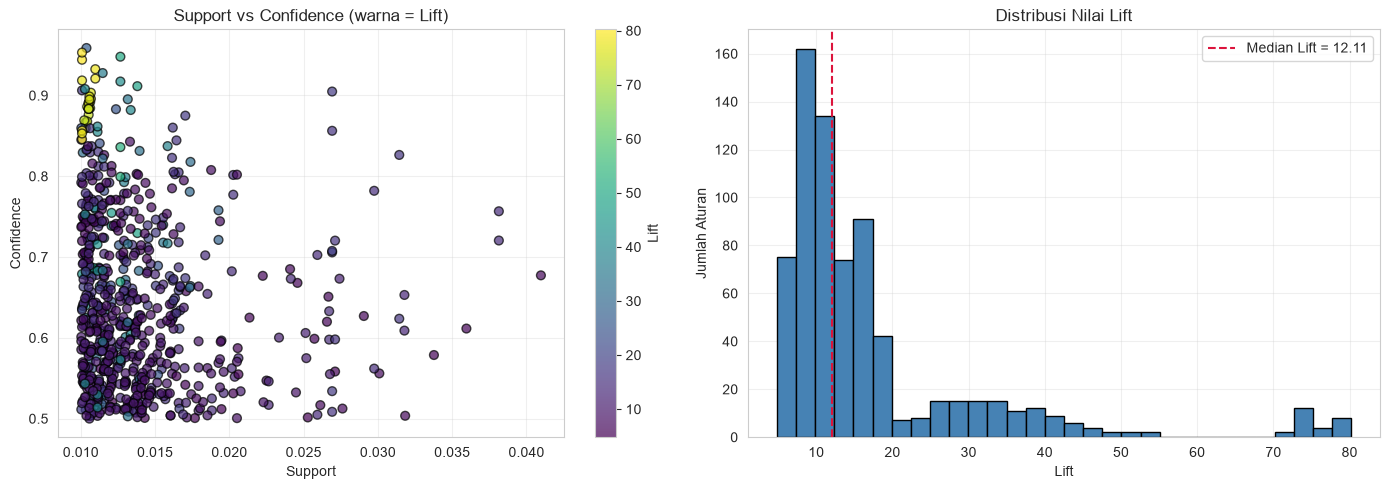

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sc = axes[0].scatter(
    rules['support'], rules['confidence'],
    c=rules['lift'], cmap='viridis', alpha=0.7, s=40, edgecolors='k'
)
axes[0].set_xlabel('Support')
axes[0].set_ylabel('Confidence')
axes[0].set_title('Support vs Confidence (warna = Lift)')
plt.colorbar(sc, ax=axes[0], label='Lift')
axes[0].grid(alpha=0.3)

axes[1].hist(rules['lift'], bins=30, color='steelblue', edgecolor='k')
axes[1].axvline(rules['lift'].median(), color='crimson', linestyle='--',
                label=f'Median Lift = {rules["lift"].median():.2f}')
axes[1].set_xlabel('Lift')
axes[1].set_ylabel('Jumlah Aturan')
axes[1].set_title('Distribusi Nilai Lift')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 7.5 Aturan dengan Confidence Tertinggi

In [18]:
top_conf = rules.sort_values('confidence', ascending=False).head(5).reset_index(drop=True)
top_conf['antecedents'] = top_conf['antecedents'].apply(lambda x: ', '.join(sorted(x)))
top_conf['consequents'] = top_conf['consequents'].apply(lambda x: ', '.join(sorted(x)))

print("5 Aturan dengan Confidence Tertinggi:")
top_conf[['antecedents', 'consequents', 'support', 'confidence', 'lift']].round(4).rename(
    columns={
        'antecedents': 'Jika Membeli',
        'consequents': 'Maka Membeli',
        'support': 'Support',
        'confidence': 'Confidence',
        'lift': 'Lift'
    }
)

5 Aturan dengan Confidence Tertinggi:


,Jika Membeli,Maka Membeli,Support,Confidence,Lift
0,"JAM MAKING SET PRINTED, SUKI SHOULDER BAG",DOTCOM POSTAGE,0.0104,0.9587,27.2665
1,"HERB MARKER PARSLEY, HERB MARKER THYME",HERB MARKER ROSEMARY,0.0101,0.9531,79.9610
2,"REGENCY TEA PLATE PINK, REGENCY TEA PLATE ROSES",REGENCY TEA PLATE GREEN,0.0127,0.9480,50.0998
3,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",HERB MARKER THYME,0.0101,0.9442,80.2200
4,HERB MARKER THYME,HERB MARKER ROSEMARY,0.0110,0.9325,78.2359


## Export Hasil

In [19]:
rules_export = rules.copy()
rules_export['antecedents'] = rules_export['antecedents'].apply(lambda x: ', '.join(sorted(x)))
rules_export['consequents'] = rules_export['consequents'].apply(lambda x: ', '.join(sorted(x)))

rules_export[[
    'antecedents', 'consequents', 'support', 'confidence', 'lift'
]].to_csv(
    '5054251017_RafaRizkiAiraSwala_Tugas_AssociationRule.csv',
    index=False
)

print(f"Berhasil export {len(rules_export)} aturan ke CSV.")

Berhasil export 727 aturan ke CSV.


## 8. Analisis & Kesimpulan

### Ringkasan Cleaning Data

Dataset awal berisi 541.909 baris transaksi. Setelah cleaning (hapus Description kosong, transaksi dibatalkan, dan Quantity ≤ 0), jumlah baris berkurang signifikan — tetapi kualitas data jauh lebih baik untuk analisis asosiasi. Tanpa langkah ini, algoritma akan tercampur noise dari retur dan error input yang menghasilkan aturan misleading.

### Parameter Algoritma

| Parameter | Nilai | Alasan |
|-----------|-------|--------|
| `min_support` | 0.01 | 1% transaksi cukup representatif dan menghasilkan itemset manageable |
| `min_confidence` | 0.5 | Filter aturan yang setidaknya benar setengah waktu |
| `max_len` itemset | 3 | Itemset > 3 cenderung terlalu jarang dan kurang actionable |
| Filter `lift > 1` | Wajib | Hanya simpan asosiasi positif yang bermakna |

### Temuan Utama

1. **Asosiasi terkuat berasal dari produk koleksi, bukan produk populer.** Ketiga aturan terbaik (lift > 79) seluruhnya berasal dari set **HERB MARKER** (Parsley, Rosemary, Thyme) — produk niche dengan support ~1% tetapi confidence 85–95%. Sebaliknya, produk paling populer seperti WHITE HANGING HEART T-LIGHT HOLDER (support 11,22%) dan JUMBO BAG RED RETROSPOT (10,39%) tidak membentuk aturan lift tinggi karena dibeli oleh banyak pelanggan berbeda dengan alasan berbeda.

2. **Pola "starter product → full collection" terkonfirmasi.** Ketiga varian Herb Marker saling memicu: membeli satu varian membuat pelanggan cenderung melengkapi dua varian lainnya. Ini karakteristik khas produk koleksi yang dijual sebagai satu set tema.

3. **Lift ekstrem (>79) muncul dari kombinasi support rendah + confidence tinggi.** Ini pola khas produk niche dengan pembeli loyal — bukan pola umum yang berlaku untuk seluruh pelanggan, tetapi sangat valuable untuk targeted marketing.

4. **Support moderat (1–5%) menunjukkan pola cukup umum** untuk strategi marketing massal, sementara support sangat rendah (<1%) menandakan pola niche yang perlu pendekatan terpisah.

### Rekomendasi Bisnis

| Strategi | Implementasi |
|----------|--------------|
| **Cross-selling** | Tampilkan consequent sebagai rekomendasi saat pelanggan melihat antecedent — khususnya untuk set Herb Marker, tampilkan ketiga varian berdampingan |
| **Bundling** | Buat paket diskon untuk pasangan produk dengan lift tinggi, misalnya "Set Lengkap Herb Marker" (Parsley + Rosemary + Thyme) |
| **Store layout** | Kelompokkan produk berasosiasi dalam satu kategori visual, misalnya kategori "Herb Marker Collection" agar pelanggan mudah menemukan semua varian |
| **Targeted promo** | Kirim voucher produk consequent ke pelanggan yang sudah membeli antecedent — untuk pelanggan yang membeli satu varian Herb Marker, kirim email follow-up promo "Lengkapi set Anda" |

### Kesimpulan

1. **Algoritma Apriori berhasil mengekstraksi pola asosiasi bermakna** dari dataset Online Retail, tetapi memerlukan pembersihan data terlebih dahulu untuk menghindari noise dari retur dan transaksi tidak valid.

2. **Metrik evaluasi saling melengkapi**: support mengukur popularitas, confidence mengukur keandalan prediksi, dan lift mengukur kekuatan asosiasi relatif terhadap random chance. **Lift adalah metrik paling penting** untuk menemukan asosiasi truly actionable — karena pada dataset ini, produk paling populer justru tidak membentuk asosiasi kuat.

3. **Tuning parameter krusial** — `min_support` terlalu rendah menghasilkan eksplosif itemset, terlalu tinggi menghilangkan pola penting. Nilai 0.01 adalah sweet spot untuk dataset sebesar ini karena cukup menangkap pola niche (seperti Herb Marker dengan support 1%) tanpa menghasilkan itemset berlebihan.

4. **Hasil analisis dapat langsung diaplikasikan** ke sistem rekomendasi produk, bundling promo, dan strategi merchandising ritel — khususnya untuk produk koleksi yang memiliki pelanggan loyal dan pola pembelian berulang.